# Part 1: trust verified labels and keep multiple reasons

**Recommended next candidate:** the compact [trusted_solution.py](trusted_solution.py) model scores **0.915337 sample F1**, versus **0.908865** for the frozen training-only Ani reference. It improves all three chronological diagnostics. The old 78-row validation check remains weaker: **0.880342 versus 0.891026**. This is a stronger local candidate, not a confirmed Kaggle win; all local comparisons have influenced development.

[Checked submission CSV](experiments/trusted_iteration/candidate/part1_trusted_submission.csv) · [model manifest](experiments/trusted_iteration/candidate/manifest.json) · [all results](experiments/trusted_iteration/all_results.csv) · [audit](experiments/trusted_iteration/final_audit.json)

## What changed

The selected model keeps the original simple architecture: standardization, a joint logistic classifier (`C=0.3`, `tol=1e-4`, `max_iter=3000`), and ten cosine neighbors with squared positive-similarity weights. The classifier score has weight 0.7; neighbors have weight 0.3. The final cutoff stays 0.3 with an argmax fallback.

Four changes address specific problems:

1. Give each generated example **one quarter** of the weight of an equivalent verified example.
2. Compute inverse reason-frequency class weights **only from verified labels**, then hold them fixed through self-training. A verified two-reason trial still contributes half to each reason in the joint logistic loss. In every CV fit, verified examples retain total effective weight 188.
3. In the neighbor vote, a trial with two reasons contributes a full binary vote to **both**. Splitting its vote in half suppressed the second reason. The resulting selection scores need not sum to one and are not calibrated marginal probabilities.
4. Use **two** pseudo-labeling passes, rebuilding from verified labels each time. Accept a row only when its highest score reaches 0.8.

No extra “Other” classifier, adaptive cutoff, GMM, PCA, graph, or ensemble survives into the selected solution. The final fit uses 235 verified trials and accepts 698, then 766 of the 1,014 originally unlabeled trials. Test inputs are opened only after fitting completes.

## Same testing contract

Every trained candidate uses the exact saved 8 × 5 folds, with 188 known fitting trials and 47 held out. All learned preprocessing and pseudo-labeling exclude held-out and Kaggle test inputs. The 1,014 originally unlabeled training trials are the only unlabeled pool. Sample F1 is pooled over 235 out-of-fold predictions per repeat and then averaged across repeats. All original files, prior models and prior submissions are preserved.

Every candidate also has the old 157/78 split and chronological cutoffs 2003/2005/2007. The chronological checks exclude later-year unlabeled features too. **These checks are now reused development diagnostics, not independent confirmation.** The Kaggle score 0.89423 belongs to Ani's original transductive submission; the active comparison here is against Ani's training-only recipe on identical folds, not against that Kaggle number.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display
PART1=Path.cwd()
if not (PART1/'data/part1_train.csv').exists():PART1=PART1/'part1'
OUT=PART1/'experiments/trusted_iteration'
comparison=pd.read_csv(OUT/'selected_comparison.csv').set_index('name')
display(comparison[['mean_f1','repeat_sd','macro_f1','delta_ani','repeat_wins_ani','fold_wins_ani','fold_ties_ani']])
display(comparison[[f'f1_{r}' for r in ['Safety','Funding','Efficacy','Recruitment','Other']]])


,mean_f1,repeat_sd,macro_f1,delta_ani,repeat_wins_ani,fold_wins_ani,fold_ties_ani
name,,,,,,,
final_r2_control,0.915337,0.004152,0.831522,0.006472,7.0,25.0,7.0
ani_train_only,0.908865,0.006631,0.822043,0.000000,0.0,0.0,40.0
dbscan_train_only,0.888316,0.003882,0.807876,-0.020550,0.0,7.0,2.0


,f1_Safety,f1_Funding,f1_Efficacy,f1_Recruitment,f1_Other
name,,,,,
final_r2_control,0.920669,0.773221,0.867622,0.977536,0.618564
ani_train_only,0.907372,0.760623,0.869526,0.972481,0.600213
dbscan_train_only,0.868164,0.753986,0.853972,0.956423,0.606836


Against Ani, the candidate wins **25 folds**, ties **7**, and loses **8**. It wins **7 of 8 repeat averages**. Macro F1 improves from 0.822043 to 0.831522; repeat SD falls from 0.006631 to 0.004152. Four reasons improve; Efficacy is slightly lower (0.867622 versus 0.869526).

The descriptive paired trial-bootstrap interval for the +0.006472 advantage is **[+0.001241, +0.012234]**. Each trial's eight predictions stay together. The interval does **not** adjust for model selection, prior searches, or correlated training fits, so it is not a formal significance claim or a forecast of leaderboard improvement.


In [2]:
display(pd.read_csv(OUT/'paired_trial_bootstrap.csv'))
diagnostics=pd.read_csv(OUT/'selected_diagnostics.csv')
display(diagnostics[['split','name','verified_fit','unlabeled_fit','held','sample_f1','macro_f1']])
display(diagnostics.pivot(index='split',columns='name',values='sample_f1'))


,name,reference,delta,lower_95,upper_95,caveat
0,final_r2_control,ani_train_only,0.006472,0.001241,0.012234,Descriptive paired trial bootstrap; not adjust...
1,final_r2_control,dbscan_train_only,0.027021,0.009113,0.046101,Descriptive paired trial bootstrap; not adjust...


,split,name,verified_fit,unlabeled_fit,held,sample_f1,macro_f1
0,original_validation,ani_train_only,157,1014,78,0.891026,0.710738
1,original_validation,final_r2_control,157,1014,78,0.880342,0.695565
2,after_2003,ani_train_only,126,60,109,0.821101,0.776237
3,after_2003,final_r2_control,126,60,109,0.824159,0.778561
4,after_2005,ani_train_only,149,302,86,0.856589,0.807949
5,after_2005,final_r2_control,149,302,86,0.860465,0.804538
6,after_2007,ani_train_only,198,724,37,0.882883,0.856518
7,after_2007,final_r2_control,198,724,37,0.887387,0.848936


name,ani_train_only,final_r2_control
split,,
after_2003,0.821101,0.824159
after_2005,0.856589,0.860465
after_2007,0.882883,0.887387
original_validation,0.891026,0.880342


The chronological gains are small but consistent: +0.003058 after 2003, +0.003876 after 2005, and +0.004505 after 2007. Those holdouts have 109, 86 and 37 known trials respectively. The old validation result is lower by 0.010684; it uses only the original 157 known fitting labels, while the eventual submission uses all 235. That difference in training population helps explain why the checks can disagree, but does not make the weaker result disappear.

## What was actually tested

The follow-up contains **66 named configurations, including repeated controls**, across seven stages. Every negative result is retained.

| Stage | Question | Finding |
|---|---|---|
| 1 | Lower pseudo-label weights; anchor class balancing; select an Other cutoff with inner CV | Lower weights alone are inconsistent. Anchored quarter weights improve later-year checks. Nested threshold tuning does not improve the original control. |
| 2 | Conditional/independent Other classifiers, extra weight on verified pairs, or binary neighbor targets | Extra classifiers and pair weights do not help. Full binary neighbor votes do. |
| 3 | Nearby C values, passes, class-balance strength, neighbor trust, and soft pseudo-labels | Two passes lead; soft pseudo-labels deteriorate strongly. |
| 4 | Relative cutoffs and expected-F1 decisions | None improves the fixed 0.3 policy. |
| 5 | Learn observed reason combinations with one multiclass logistic model | Best combination model scores 0.909273; below the selected model. |
| 6 | Combine stronger regularization with fewer passes; check confidence thresholds | Two passes, C0.3 and confidence0.8 remain the selected single model. |
| 7 | Three fixed equal-weight averages | Averaging C0.1/C0.3 scores 0.915514, only 0.000177 higher, with higher repeat SD and fewer repeat wins. Keep the single model. |

For Other-threshold selection, each outer training set is divided into three stratified inner folds (seed 8128). Inner held-out inputs are excluded from fitting, including scaling and pseudo-labeling. Select a cutoff from the fixed list 0.3/0.25/0.35/0.2/0.4/0.5/0.1 using total sample F1, with fixed tie preference. All 80 outer threshold selections (240 inner fits) are saved and independently rescored. Their choices vary considerably, which is a reason to retain the fixed policy.


In [3]:
results=pd.read_csv(OUT/'all_results.csv')
display(results[~results.name.isin(['ani_train_only','dbscan_train_only'])].sort_values('mean_f1',ascending=False).head(15)[['stage','name','mean_f1','macro_f1','repeat_sd','delta_ani']])
display(pd.read_csv(OUT/'error_analysis/prior_other_and_multilabel_errors.csv'))


,stage,name,mean_f1,macro_f1,repeat_sd,delta_ani
75,07_fixed_equal_averages,average_C0.3_C0.1,0.915514,0.831481,0.004935,0.006649
28,03_trusted_multilabel_refinement,binary_rounds_2,0.915337,0.831522,0.004152,0.006472
42,04_sample_f1_decisions,decision_r2_fixed,0.915337,0.831522,0.004152,0.006472
67,06_final_regularization_check,final_r2_control,0.915337,0.831522,0.004152,0.006472
54,05_joint_reason_combinations,trusted_r2_control,0.915337,0.831522,0.004152,0.006472
29,03_trusted_multilabel_refinement,binary_C_0.1,0.915071,0.831096,0.006508,0.006206
76,07_fixed_equal_averages,average_rounds2_3,0.914716,0.829635,0.004302,0.005851
68,06_final_regularization_check,final_r2_C0.1,0.914716,0.832129,0.005542,0.005851
30,03_trusted_multilabel_refinement,binary_rounds_5,0.914539,0.826401,0.004674,0.005674
31,03_trusted_multilabel_refinement,binary_trusted_control,0.914184,0.826477,0.004565,0.005319


,model,group,trials,mean_f1,other_false_negatives_per_repeat,other_false_positives_per_repeat
0,simple3,single_reason,216,0.930459,7.125,8.750
1,simple3,two_reasons,19,0.716886,8.750,0.250
2,simple3,other_only,26,0.697115,7.125,0.000
3,simple3,recruitment_other,9,0.638889,8.750,0.000
4,simple3,without_other,200,0.953625,0.000,9.000
5,ani_train_only,single_reason,216,0.925058,7.125,10.375
6,ani_train_only,two_reasons,19,0.724781,8.375,0.125
7,ani_train_only,other_only,26,0.701923,7.125,0.000
8,ani_train_only,recruitment_other,9,0.662037,8.375,0.000
9,ani_train_only,without_other,200,0.946875,0.000,10.500


## What the error analysis does and does not show

There are 19 two-reason trials among the 235 known trials. The prior simplified model scored only 0.716886 on that subgroup, versus Ani's 0.724781. The new selected model reaches **0.758772**. Its single-reason subgroup also improves over Ani: 0.929109 versus 0.925058.

However, the nine Recruitment+Other trials remain difficult. Their sample F1 is **0.662037 for both Ani and the selected model**. Other-only trial sample F1 also ties Ani at 0.701923. The improved overall Other F1 therefore should not be described as solving those missed second reasons; fewer false-positive Other assignments help. Targeted Other classifiers were tested and rejected. This remains a limitation.

## Artifacts and independent checks

- `trusted_solution.py` is the compact implementation with fixed settings, independent of the experimental model class.
- Its scores and labels reproduce all **40** selected CV fits and all **4** diagnostic fits. The raw weight calculation is independently checked: known effective mass stays 188 inside each CV fit, and each generated label gets its declared quarter weight before the fixed class multiplier.
- `candidate/trusted_two_pass.joblib` reloads with exactly identical test scores. The CSV has 312 unique IDs, correct order and nonempty valid labels.
- `candidate/generated_labels.csv` separates accepted fitting targets from final predictions for all unlabeled rows. `candidate/part1_train_augmented.csv` preserves every original verified label and marks generated labels. Part 2 data is unchanged.
- Original benchmark/data/model/submission checksums and the prior simple candidate's checksums still match. No upload, commit or push was performed.

The assignment's unsupervised label-generation comparisons remain in the prior notebooks, including the saved K-means augmented dataset. This selected recipe uses self-training; it should not be described as a clustering model. Submit the prior method comparisons alongside this follow-up if preparing the project report.


In [4]:
display(json.loads((OUT/'final_audit.json').read_text()))
manifest=json.loads((OUT/'candidate/manifest.json').read_text())
display({k:manifest[k] for k in ['status','known_labels','final_generated_counts','final_fit_weights',
                               'independent_fold_replays','independent_diagnostic_replays','kaggle_score','versions']})


{'reference_control_all40folds_reproduced': True,
 'outer_fit_role_audits': 2520,
 'inner_threshold_selections_rescored': 80,
 'inner_fit_count': 240,
 'inner_labels_aligned_with_saved_outer_training_ids': True,
 'candidate_fold_replays': 40,
 'candidate_diagnostic_replays': 4,
 'candidate_artifact_and_source_checksums_valid': True,
 'submission_rows': 312,
 'sample_submission_order_and_valid_labels': True,
 'protected_originals_unchanged': True}

{'status': 'unsubmitted recommended candidate; fixed benchmark reference unchanged',
 'known_labels': 235,
 'final_generated_counts': [698, 766],
 'final_fit_weights': [{'step': 0, 'known': 235.0, 'generated': 0.0},
  {'step': 1, 'known': 235.0, 'generated': 105.88540633088871},
  {'step': 2, 'known': 235.0, 'generated': 123.2000130320679}],
 'independent_fold_replays': 40,
 'independent_diagnostic_replays': 4,
 'kaggle_score': None,
 'versions': {'python': '3.12.13',
  'sklearn': '1.9.0',
  'numpy': '2.5.2',
  'pandas': '3.0.5',
  'joblib': '1.6.0'}}

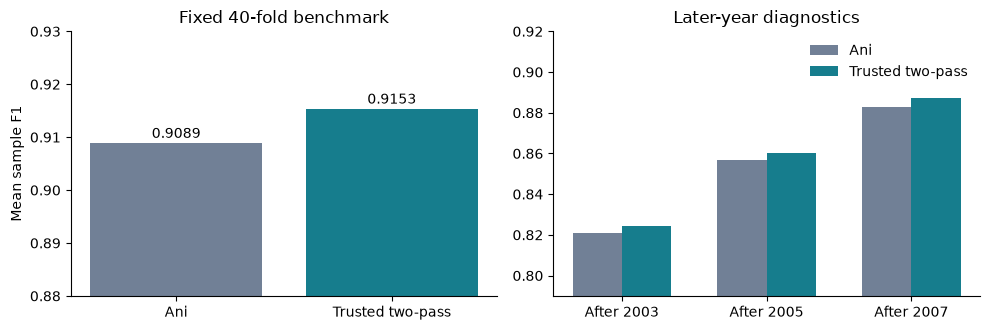

In [5]:
# Standalone figure; higher F1 is better. These are development comparisons.
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,3.4))
models=['ani_train_only','final_r2_control'];labels=['Ani','Trusted two-pass']
axes[0].bar(labels,comparison.loc[models,'mean_f1'],color=['#718096','#167d8d'])
axes[0].set_ylim(.88,.93);axes[0].set_ylabel('Mean sample F1');axes[0].set_title('Fixed 40-fold benchmark')
for i,value in enumerate(comparison.loc[models,'mean_f1']):axes[0].text(i,value+.001,f'{value:.4f}',ha='center')
wide=diagnostics.pivot(index='split',columns='name',values='sample_f1').loc[['after_2003','after_2005','after_2007']]
x=np.arange(len(wide));w=.34
for i,(model,label,color) in enumerate(zip(models,labels,['#718096','#167d8d'])):
    axes[1].bar(x+(i-.5)*w,wide[model],w,label=label,color=color)
axes[1].set_xticks(x,['After 2003','After 2005','After 2007']);axes[1].set_ylim(.79,.92)
axes[1].set_title('Later-year diagnostics');axes[1].legend(frameon=False)
for ax in axes:ax.spines[['top','right']].set_visible(False)
fig.tight_layout();fig.savefig(OUT/'comparison.png',dpi=180);fig.savefig(OUT/'comparison.pdf');plt.show()


## Complete new source and reproduction

The following executable cells load the complete new source into separate modules. The earlier `simple_models.py` and `simple_benchmark.py` helpers are unchanged and are included in `simple_methodical.ipynb`; the supplied CSVs and saved reference folds/predictions remain required. Use the existing repository environment or `requirements-simple.txt`.

The last cell defaults to saved results. Set `RERUN_ALL=True` to rerun all seven frozen stages, the independent implementation checks and artifact generation. The stage folders also preserve the source snapshots used at the time of each experiment. The original reference never changes during this workflow.


In [6]:
import sys,types
from IPython.core.magic import register_cell_magic
sys.path.insert(0,str(PART1))
@register_cell_magic
def source_module(name,source):
    module=types.ModuleType(name.strip());module.__file__=str(PART1/(name.strip()+'.py'))
    sys.modules[name.strip()]=module
    exec(compile(source,module.__file__,'exec'),module.__dict__)
    print('Loaded',name.strip())


In [7]:
%%source_module trusted_models
"""Focused follow-up: verified-label trust and multilabel decision rules.

The default reproduces the previous three-pass simple model exactly.
"""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, normalize

from simple_models import REASONS, FEATURES, decide

LABELSETS = ((np.arange(1, 32)[:, None] >> np.arange(5)) & 1)
F1_UTILITY = 2 * (LABELSETS @ LABELSETS.T) / (LABELSETS.sum(axis=1)[:, None] + LABELSETS.sum(axis=1)[None, :])


def expected_f1_labels(P, independent=False):
    """Choose labels by expected sample F1 under a declared posterior assumption."""
    if independent:
        posterior = np.prod(np.where(LABELSETS[None, :, :], P[:, None, :], 1-P[:, None, :]), axis=2)
    else:
        posterior = np.zeros((len(P), 31))
        posterior[:, (1 << np.arange(5))-1] = P
    return LABELSETS[(posterior @ F1_UTILITY.T).argmax(axis=1)].copy()


def sample_f1(Y, prediction):
    return np.mean(2 * (Y * prediction).sum(axis=1) / (Y.sum(axis=1) + prediction.sum(axis=1)))


class TrustedReasonClassifier:
    def __init__(self, spec=None):
        self.spec = dict(spec or {})

    def fit(self, X, Y, U):
        X, Y, U = np.asarray(X), np.asarray(Y, int), np.asarray(U)
        s = self.spec
        assert Y.shape == (len(X), 5) and np.isin(Y, [0, 1]).all() and (Y.sum(axis=1) > 0).all()
        self.scaler_ = StandardScaler().fit(np.vstack([X, U]))
        Z, V = self.scaler_.transform(X), self.scaler_.transform(U)
        if s.get('geometry') == 'scalar':
            self.scaler_.scale_[:] = np.sqrt(self.scaler_.var_.mean())
            Z, V = self.scaler_.transform(X), self.scaler_.transform(U)
        verified_counts = (Y / Y.sum(axis=1, keepdims=True)).sum(axis=0)
        Za, Ya = Z, Y
        self.round_audit_ = []
        self.accepted_mask_ = np.zeros(len(U), bool)
        self.accepted_labels_ = np.empty((0, 5), int)
        for step in range(s.get('rounds', 3) + 1):
            row, reason = np.nonzero(Ya)
            weight = Ya[row, reason] / Ya.sum(axis=1)[row]
            counts = np.bincount(reason, weights=weight, minlength=5)
            origin_weight = np.where(row < len(X), 1., s.get('pseudo_weight', 1.))
            source = s.get('balance_source', 'augmented')
            if source == 'verified':
                counts = verified_counts
            elif source == 'weighted':
                counts = np.bincount(reason, weights=weight * origin_weight, minlength=5)
            elif source != 'augmented':
                raise ValueError(source)
            weight *= (counts.mean() / counts[reason]) ** s.get('balance_power', 1.)
            weight *= origin_weight
            weight *= np.where((row < len(X)) & (Ya.sum(axis=1)[row] > 1), s.get('verified_pair_weight', 1.), 1.)
            if s.get('normalize_mass', False):
                weight *= len(Za) / weight.sum()
            self.logistic_ = LogisticRegression(C=s.get('C', .3), max_iter=3000, tol=1e-4)
            self.logistic_.fit(Za[row], reason, sample_weight=weight)
            self.neighbor_X_ = normalize(Za)
            self.neighbor_Y_ = Ya if s.get('binary_neighbor_targets', False) else Ya / Ya.sum(axis=1, keepdims=True)
            self.neighbor_labels_ = (Ya >= .3).astype(int)
            self.neighbor_trust_ = np.r_[np.ones(len(X)), np.full(len(Za)-len(X), s.get('neighbor_pseudo_weight', 1.))]
            self.round_audit_.append(dict(step=step, generated=len(Za)-len(X),
                                           effective_verified_weight=float(weight[row < len(X)].sum()),
                                           effective_generated_weight=float(weight[row >= len(X)].sum()),
                                           class_counts=counts.tolist()))
            if step == s.get('rounds', 3):
                break
            P = self._base_scaled(V)
            self.accepted_mask_ = P.max(axis=1) >= s.get('confidence', .8)
            self.accepted_labels_ = P[self.accepted_mask_].copy() if s.get('soft_pseudo', False) else decide(P[self.accepted_mask_], .3)
            Za = np.vstack([Z, V[self.accepted_mask_]])
            Ya = np.vstack([Y, self.accepted_labels_])
        self.other_model_ = None
        self.other_constant_ = None
        self.other_kind_ = s.get('other_head')
        if self.other_kind_:
            fitting = Y[:, 3] == 1 if self.other_kind_.startswith('conditional') else np.ones(len(Y), bool)
            self.other_known_X_ = Z[fitting]
            self.other_known_Y_ = Y[fitting, 4]
            if self.other_kind_.endswith('logistic'):
                if len(np.unique(Y[fitting, 4])) == 1:
                    self.other_constant_ = float(Y[fitting, 4].mean())
                else:
                    self.other_model_ = LogisticRegression(C=s.get('other_C', 1.), max_iter=3000, tol=1e-6,
                                                           class_weight=s.get('other_class_weight')).fit(Z[fitting], Y[fitting, 4])
        return self

    def _base_scaled(self, Z):
        P = np.zeros((len(Z), 5))
        P[:, self.logistic_.classes_] = self.logistic_.predict_proba(Z)
        similarity = normalize(Z) @ self.neighbor_X_.T
        neighbors = np.argsort(-similarity, axis=1)[:, :self.spec.get('knn_count', 10)]
        weight = np.take_along_axis(similarity, neighbors, axis=1).clip(0) ** 2
        weight *= self.neighbor_trust_[neighbors]
        local = (weight[:, :, None] * self.neighbor_Y_[neighbors]).sum(axis=1) / (weight.sum(axis=1, keepdims=True) + 1e-9)
        mix = self.spec.get('knn_weight', .3)
        return (1-mix) * P + mix * local

    def predict_proba(self, X):
        Z = self.scaler_.transform(X)
        P = self._base_scaled(Z)
        if self.other_kind_:
            if self.other_constant_ is not None:
                other = np.full(len(Z), self.other_constant_)
            elif self.other_kind_.endswith('logistic'):
                other = self.other_model_.predict_proba(Z)[:, 1]
            else:
                similarity = normalize(Z) @ normalize(self.other_known_X_).T
                indices = np.argsort(-similarity, axis=1)[:, :self.spec.get('other_k', 5)]
                weights = np.take_along_axis(similarity, indices, axis=1).clip(0) ** 2
                other = (weights * self.other_known_Y_[indices]).sum(axis=1) / (weights.sum(axis=1) + 1e-9)
            if self.other_kind_.startswith('conditional'):
                eligible = decide(P, .3)[:, 3] == 1
                P[eligible, 4] = np.maximum(P[eligible, 4], other[eligible])
            else:
                P[:, 4] = other
        return P

    def predict(self, X):
        P = self.predict_proba(X)
        decision = self.spec.get('decision')
        if decision == 'relative':
            return (P >= .5 * P.max(axis=1, keepdims=True)).astype(int)
        if decision in ('expected_single', 'expected_independent'):
            return expected_f1_labels(P, independent=decision == 'expected_independent')
        if decision == 'expected_neighbors':
            Z = self.scaler_.transform(X)
            posterior = np.zeros((len(Z), 31))
            lr = np.zeros((len(Z), 5))
            lr[:, self.logistic_.classes_] = self.logistic_.predict_proba(Z)
            mix = self.spec.get('knn_weight', .3)
            posterior[:, (1 << np.arange(5))-1] = (1-mix) * lr
            similarities = normalize(Z) @ self.neighbor_X_.T
            ix = np.argsort(-similarities, axis=1)[:, :self.spec.get('knn_count', 10)]
            w = np.take_along_axis(similarities, ix, axis=1).clip(0) ** 2
            w *= self.neighbor_trust_[ix]
            w /= w.sum(axis=1, keepdims=True) + 1e-9
            masks = self.neighbor_labels_ @ (1 << np.arange(5))
            for i in range(len(Z)):
                np.add.at(posterior[i], masks[ix[i]]-1, mix*w[i])
            return LABELSETS[(posterior @ F1_UTILITY.T).argmax(axis=1)].copy()
        return decide(P, self.spec.get('cutoffs', .3))


def inner_other_threshold(X, Y, U, spec, seed=8128):
    """Pick one cutoff from inner OOF predictions; outer rows never enter fit."""
    model_spec = {k: v for k, v in spec.items() if k not in ('decision', 'cutoffs')}
    splitter = StratifiedKFold(3, shuffle=True, random_state=seed)
    P = np.full(Y.shape, np.nan, dtype=float)
    folds = np.full(len(Y), -1)
    for fold, (fit, held) in enumerate(splitter.split(X, Y[:, 4])):
        model = TrustedReasonClassifier(model_spec).fit(X[fit], Y[fit], U)
        P[held] = model.predict_proba(X[held])
        folds[held] = fold
    assert np.isfinite(P).all()
    # Fixed candidate list and tie preference; optimize total sample F1.
    thresholds = [.3, .25, .35, .2, .4, .5, .1]
    scores = []
    for threshold in thresholds:
        cutoffs = np.array([.3, .3, .3, .3, threshold])
        scores.append(float(sample_f1(Y, decide(P, cutoffs))))
    best = next(i for i, score in enumerate(scores) if score >= max(scores)-1e-12)
    cutoff = thresholds[best]
    return np.array([.3, .3, .3, .3, cutoff]), dict(threshold=cutoff, candidates=thresholds, scores=scores,
                                                 inner_fold=folds.tolist(), inner_probabilities=P.tolist())


class LabelsetReasonClassifier:
    """One ordinary multiclass logistic model for the observed reason combinations."""
    def __init__(self, spec):
        self.spec = dict(spec)

    def fit(self, X, Y, U):
        X, Y, U = np.asarray(X), np.asarray(Y, int), np.asarray(U)
        s = self.spec
        self.scaler_ = StandardScaler().fit(np.vstack([X, U]))
        Z, V = self.scaler_.transform(X), self.scaler_.transform(U)
        self.labelsets_, classes = np.unique(Y, axis=0, return_inverse=True)
        counts = np.bincount(classes, minlength=len(self.labelsets_))
        reason_counts = (Y / Y.sum(axis=1, keepdims=True)).sum(axis=0)
        balancing = s.get('labelset_balance', 'reason')
        if balancing == 'combination':
            weights = counts.mean() / counts
        elif balancing == 'reason':
            weights = (self.labelsets_ @ (reason_counts.mean() / reason_counts)) / self.labelsets_.sum(axis=1)
        elif balancing == 'none':
            weights = np.ones(len(counts))
        else:
            raise ValueError(balancing)
        Za, ca = Z, classes
        self.round_audit_ = []
        self.accepted_mask_ = np.zeros(len(U), bool)
        self.accepted_labels_ = np.empty((0, 5), int)
        for step in range(s.get('rounds', 2)+1):
            row_weight = weights[ca] * np.r_[np.ones(len(X)), np.full(len(Za)-len(X), s.get('pseudo_weight', .25))]
            self.logistic_ = LogisticRegression(C=s.get('C', .3), max_iter=3000, tol=1e-4).fit(Za, ca, sample_weight=row_weight)
            self.neighbor_X_ = normalize(Za)
            self.neighbor_classes_ = ca
            self.round_audit_.append(dict(step=step,generated=len(Za)-len(X),effective_verified_weight=float(row_weight[:len(X)].sum()),
                                         effective_generated_weight=float(row_weight[len(X):].sum()),class_counts=counts.tolist()))
            if step == s.get('rounds', 2):
                break
            posterior = self._posterior_scaled(V)
            self.accepted_mask_ = posterior.max(axis=1) >= s.get('confidence', .8)
            labels = posterior[self.accepted_mask_].argmax(axis=1)
            self.accepted_labels_ = self.labelsets_[labels]
            Za = np.vstack([Z,V[self.accepted_mask_]])
            ca = np.r_[classes,labels]
        return self

    def _posterior_scaled(self, Z):
        P = np.zeros((len(Z),len(self.labelsets_)))
        P[:,self.logistic_.classes_] = self.logistic_.predict_proba(Z)
        similarity = normalize(Z) @ self.neighbor_X_.T
        ix = np.argsort(-similarity,axis=1)[:,:10]
        w = np.take_along_axis(similarity,ix,axis=1).clip(0)**2
        w /= w.sum(axis=1,keepdims=True)+1e-9
        local = np.zeros_like(P)
        for row in range(len(Z)):
            np.add.at(local[row],self.neighbor_classes_[ix[row]],w[row])
        return .7*P+.3*local

    def predict_proba(self, X):
        return self._posterior_scaled(self.scaler_.transform(X)) @ self.labelsets_

    def predict(self, X):
        posterior = self._posterior_scaled(self.scaler_.transform(X))
        if self.spec.get('decision') == 'expected_labelset':
            utility = 2 * (LABELSETS @ self.labelsets_.T) / (LABELSETS.sum(axis=1)[:,None]+self.labelsets_.sum(axis=1)[None,:])
            return LABELSETS[(posterior @ utility.T).argmax(axis=1)].copy()
        return decide(posterior @ self.labelsets_, .3)


def fit_and_predict(X, Y, U, Q, spec):
    audit = {}
    cutoffs = spec.get('cutoffs', .3)
    if spec.get('decision') == 'inner_other':
        cutoffs, audit = inner_other_threshold(X, Y, U, spec)
    factory = LabelsetReasonClassifier if spec.get('family') == 'labelset' else TrustedReasonClassifier
    model = factory(spec).fit(X, Y, U)
    P = model.predict_proba(Q)
    prediction = decide(P, cutoffs) if spec.get('decision') == 'inner_other' else model.predict(Q)
    return model, P, prediction, dict(cutoffs=np.asarray(cutoffs).tolist(), inner=audit, training=model.round_audit_)


Loaded trusted_models


In [8]:
%%source_module trusted_benchmark
"""Continue on the existing benchmark, preserving earlier experiments unchanged."""
import argparse
import json
from pathlib import Path
import shutil
import time
import warnings

import numpy as np
import pandas as pd
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

from simple_models import FEATURES, REASONS
from simple_benchmark import ROOT, BASE, digest, load_data, report, metrics
from trusted_models import TrustedReasonClassifier, fit_and_predict

OUT = ROOT / 'experiments/trusted_iteration'


def run(stage_name, specs):
    stage = OUT / stage_name
    stage.mkdir(parents=True, exist_ok=True)
    known, unknown = load_data()
    X, Y, U = known[FEATURES].to_numpy(), known[REASONS].to_numpy(int), unknown[FEATURES].to_numpy()
    paths = [BASE / 'splits' / f'repeat{r}.csv' for r in range(8)]
    folds = np.array([pd.read_csv(p).set_index('ID').loc[known.ID, 'fold'].to_numpy() for p in paths])
    protocol = dict(stage=stage_name, specs=specs,
                    question='Effect of pseudo-label trust, anchored class balancing and targeted Other decisions.',
                    fixed_splits={p.name:digest(p) for p in paths},
                    inputs={p.name:digest(p) for p in [ROOT/'data/part1_train.csv', ROOT/'data/part1_val.csv']},
                    fitting='188 known + 1014 originally unlabeled; all 47 held and all test inputs excluded from every fit.',
                    inner_tuning='When enabled: 3 stratified inner folds, seed8128; fit excludes inner held inputs; select Other cutoff by pooled sample F1, fixed tie preference.',
                    interpretation='Reused development benchmark. Later-year diagnostics have also been seen in prior work; no untouched final test claim.')
    path = stage/'protocol.json'
    if path.exists():
        assert json.loads(path.read_text()) == protocol
    else:
        path.write_text(json.dumps(protocol, indent=2)+'\n')
    for filename in ['trusted_models.py', 'trusted_benchmark.py']:
        target=stage/filename
        if not target.exists():
            shutil.copyfile(ROOT/filename, target)
    predictions = {s['name']:np.full((8,235,5), -1, np.int8) for s in specs}
    probabilities = {s['name']:np.full((8,235,5), np.nan) for s in specs}
    audits=[]
    start=time.time()
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        for repeat in range(8):
            for fold in range(5):
                held=folds[repeat]==fold
                assert held.sum()==47 and (~held).sum()==188
                for s in specs:
                    model,P,pred,audit=fit_and_predict(X[~held],Y[~held],U,X[held],s)
                    assert np.isfinite(P).all() and np.isin(pred,[0,1]).all() and pred.sum(axis=1).min()>=1
                    probabilities[s['name']][repeat,held]=P
                    predictions[s['name']][repeat,held]=pred
                    audit.update(repeat=repeat, fold=fold, name=s['name'], fit_ids=known.loc[~held,'ID'].tolist(), held_ids=known.loc[held,'ID'].tolist())
                    audits.append(audit)
            print(f'{stage_name}: repeat {repeat+1}/8, {time.time()-start:.1f}s', flush=True)
    np.savez_compressed(stage/'predictions.npz', ids=known.ID.to_numpy(str), truth=Y, folds=folds, **predictions)
    np.savez_compressed(stage/'probabilities.npz', **probabilities)
    (stage/'fit_audits.json').write_text(json.dumps(audits, separators=(',',':'))+'\n')
    with np.load(stage/'predictions.npz') as disk:
        saved={s['name']:disk[s['name']] for s in specs}
    report(stage,known,folds,saved)
    return stage


def diagnostics(stage_name):
    stage=OUT/stage_name
    specs=json.loads((stage/'protocol.json').read_text())['specs']
    known,unknown=load_data()
    reference=pd.read_csv(ROOT/'experiments/simple_methodical/verification/diagnostic_predictions.csv')
    reference=reference[reference.name=='ani_train_only']
    settings=dict(cutoffs=[2003,2005,2007], originally_unlabeled_policy='Exclude years after cutoff, including their inputs.',
                  old_validation='157 original known fit; 78 former-validation held, all1014 unknown allowed.',
                  caveat='Diagnostics reused during development, not new independent confirmation.')
    (stage/'diagnostic_protocol.json').write_text(json.dumps(settings,indent=2)+'\n')
    splits=[('original_validation', np.arange(len(known))<157, np.ones(len(unknown),bool))]
    for year in [2003,2005,2007]:
        splits.append((f'after_{year}',known.start_year.to_numpy()<=year,unknown.start_year.to_numpy()<=year))
    rows, outputs, audits=[],[],[]
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('error', ConvergenceWarning)
        for label,fit,unlab in splits:
            X,Y,U=known.loc[fit,FEATURES].to_numpy(),known.loc[fit,REASONS].to_numpy(int),unknown.loc[unlab,FEATURES].to_numpy()
            Q,truth=known.loc[~fit,FEATURES].to_numpy(),known.loc[~fit,REASONS].to_numpy(int)
            ref=reference[reference.split==label].set_index('ID').loc[known.loc[~fit,'ID']]
            np.testing.assert_array_equal(ref[[f'actual_{r}' for r in REASONS]],truth)
            refpred=ref[[f'predicted_{r}' for r in REASONS]].to_numpy(int)
            rows.append(dict(split=label,name='ani_train_only',verified_fit=len(X),unlabeled_fit=len(U),held=len(Q),**metrics(truth,refpred)))
            for s in specs:
                model,P,pred,audit=fit_and_predict(X,Y,U,Q,s)
                rows.append(dict(split=label,name=s['name'],verified_fit=len(X),unlabeled_fit=len(U),held=len(Q),**metrics(truth,pred)))
                df=pd.DataFrame(dict(ID=known.loc[~fit,'ID'],split=label,name=s['name']))
                for j,r in enumerate(REASONS):
                    df[f'actual_{r}']=truth[:,j];df[f'predicted_{r}']=pred[:,j];df[f'probability_{r}']=P[:,j]
                outputs.append(df)
                audit.update(split=label,name=s['name']);audits.append(audit)
            print(label,{r['name']:round(r['sample_f1'],6) for r in rows if r['split']==label},flush=True)
    pd.DataFrame(rows).to_csv(stage/'diagnostic_scores.csv',index=False)
    pd.concat(outputs).to_csv(stage/'diagnostic_predictions.csv',index=False)
    (stage/'diagnostic_audits.json').write_text(json.dumps(audits,separators=(',',':'))+'\n')


if __name__=='__main__':
    p=argparse.ArgumentParser()
    p.add_argument('--stage',required=True)
    p.add_argument('--specs',type=Path)
    p.add_argument('--diagnostics',action='store_true')
    a=p.parse_args()
    if a.specs:
        run(a.stage,json.loads(a.specs.read_text()))
    if a.diagnostics:
        diagnostics(a.stage)


Loaded trusted_benchmark


In [9]:
%%source_module trusted_average
"""Three predeclared equal-weight averages; reuse paired held-out scores."""
import json
from pathlib import Path
import numpy as np
import pandas as pd
from simple_benchmark import BASE, ROOT, load_data, report, metrics, digest
from simple_models import REASONS, decide
from trusted_benchmark import OUT


def main():
    stage = OUT/'07_fixed_equal_averages'
    stage.mkdir(exist_ok=True)
    source = OUT/'06_final_regularization_check'
    previous = OUT/'02_other_and_paired_labels'
    known, _ = load_data()
    folds = np.array([pd.read_csv(BASE/'splits'/f'repeat{r}.csv').set_index('ID').loc[known.ID,'fold'].to_numpy() for r in range(8)])
    combinations = {
        'average_C0.3_C0.1': ['final_r2_control','final_r2_C0.1'],
        'average_rounds2_3': ['final_r2_control','binary_neighbor_targets'],
        'average_trusted_ani': ['final_r2_control','ani_train_only'],
    }
    protocol = dict(combinations=combinations,weights=[.5,.5],cutoff=.3,
                    reason='Fixed equal averages check whether nearby simple fits reduce variability. No fitted ensemble or weight search.',
                    inputs={str(p.relative_to(ROOT)):digest(p) for p in [source/'probabilities.npz',previous/'probabilities.npz']},
                    fitting='Reuse strict held-out scores from the exact40folds; no new feature or label fitting.')
    (stage/'protocol.json').write_text(json.dumps(protocol,indent=2)+'\n')
    data=np.load(source/'probabilities.npz')
    components={name:data[name] for name in ['final_r2_control','final_r2_C0.1']}
    components['binary_neighbor_targets']=np.load(previous/'probabilities.npz')['binary_neighbor_targets']
    ani=[]
    for repeat in range(8):
        df=pd.concat([pd.read_csv(BASE/'predictions'/f'repeat{repeat}_fold{f}__ani_train_only.csv') for f in range(5)]).set_index('ID').loc[known.ID]
        ani.append(df[[f'probability_{r}' for r in REASONS]].to_numpy())
    components['ani_train_only']=np.stack(ani)
    probabilities={name:.5*components[a]+.5*components[b] for name,(a,b) in combinations.items()}
    predictions={name:np.stack([decide(p,.3) for p in ps]) for name,ps in probabilities.items()}
    np.savez_compressed(stage/'probabilities.npz',**probabilities)
    np.savez_compressed(stage/'predictions.npz',ids=known.ID.to_numpy(str),truth=known[REASONS].to_numpy(int),folds=folds,**predictions)
    report(stage,known,folds,predictions)
    frame=pd.concat([pd.read_csv(source/'diagnostic_predictions.csv'),pd.read_csv(previous/'diagnostic_predictions.csv'),
                     pd.read_csv(ROOT/'experiments/simple_methodical/verification/diagnostic_predictions.csv')],ignore_index=True)
    rows,output=[],[]
    for split in ['original_validation','after_2003','after_2005','after_2007']:
        refs=frame[(frame.split==split)&(frame.name=='ani_train_only')].drop_duplicates('ID').set_index('ID')
        truth=refs[[f'actual_{r}' for r in REASONS]].to_numpy(int)
        for name,(a,b) in combinations.items():
            pair=[]
            for component in [a,b]:
                d=frame[(frame.split==split)&(frame.name==component)].drop_duplicates('ID').set_index('ID').loc[refs.index]
                np.testing.assert_array_equal(d[[f'actual_{r}' for r in REASONS]],truth)
                pair.append(d[[f'probability_{r}' for r in REASONS]].to_numpy())
            P=.5*pair[0]+.5*pair[1];pred=decide(P,.3)
            rows.append(dict(split=split,name=name,held=len(truth),**metrics(truth,pred)))
            out=pd.DataFrame(dict(ID=refs.index,split=split,name=name))
            for j,r in enumerate(REASONS):
                out[f'actual_{r}']=truth[:,j];out[f'probability_{r}']=P[:,j];out[f'predicted_{r}']=pred[:,j]
            output.append(out)
    pd.DataFrame(rows).to_csv(stage/'diagnostic_scores.csv',index=False)
    pd.concat(output).to_csv(stage/'diagnostic_predictions.csv',index=False)
    print(pd.DataFrame(rows)[['split','name','sample_f1','macro_f1']].to_string(index=False))


if __name__=='__main__':
    main()


Loaded trusted_average


In [10]:
%%source_module trusted_solution
"""Selected simple recipe: trust verified labels, retain both neighbor reasons.

Input embeddings: emb_0..149. Label order: Safety, Funding, Efficacy,
Recruitment, Other. All preprocessing excludes query/test inputs.
"""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, normalize


def select_reasons(scores):
    labels = (scores >= .3).astype(int)
    empty = np.flatnonzero(labels.sum(axis=1) == 0)
    labels[empty, scores[empty].argmax(axis=1)] = 1
    return labels


class TrustedTwoPassClassifier:
    def fit(self, known_embeddings, known_labels, unlabeled_embeddings):
        X = np.asarray(known_embeddings, float)
        Y = np.asarray(known_labels, int)
        U = np.asarray(unlabeled_embeddings, float)
        if X.shape[1] != 150 or U.shape[1] != 150 or Y.shape != (len(X), 5):
            raise ValueError('Expected 150 embedding columns and five reason labels.')
        if not np.isin(Y, [0, 1]).all() or (Y.sum(axis=1) == 0).any() or (Y.sum(axis=0) == 0).any():
            raise ValueError('Known rows need binary, nonempty labels representing all five reasons.')
        self.scaler_ = StandardScaler().fit(np.vstack([X, U]))
        Z, V = self.scaler_.transform(X), self.scaler_.transform(U)
        # Fix class weights using verified labels; generated labels never change them.
        counts = (Y / Y.sum(axis=1, keepdims=True)).sum(axis=0)
        self.class_weights_ = counts.mean() / counts
        Za, Ya = Z, Y
        self.round_counts_ = []
        self.fit_weight_audit_ = []
        for step in range(3):  # Initial fit, then two augmented refits.
            row, reason = np.nonzero(Ya)
            weight = self.class_weights_[reason] / Ya.sum(axis=1)[row]
            weight *= np.where(row < len(X), 1., .25)
            self.fit_weight_audit_.append(dict(step=step, known=float(weight[row < len(X)].sum()),
                                               generated=float(weight[row >= len(X)].sum())))
            self.logistic_ = LogisticRegression(C=.3, max_iter=3000, tol=1e-4)
            self.logistic_.fit(Za[row], reason, sample_weight=weight)
            self.neighbor_X_ = normalize(Za)
            self.neighbor_Y_ = Ya.copy()  # A two-reason neighbor votes fully for both.
            if step == 2:
                break
            scores = self._scores_scaled(V)
            self.accepted_mask_ = scores.max(axis=1) >= .8
            self.accepted_labels_ = select_reasons(scores[self.accepted_mask_])
            self.round_counts_.append(int(self.accepted_mask_.sum()))
            Za = np.vstack([Z, V[self.accepted_mask_]])
            Ya = np.vstack([Y, self.accepted_labels_])
        return self

    def _scores_scaled(self, Z):
        scores = np.zeros((len(Z), 5))
        scores[:, self.logistic_.classes_] = self.logistic_.predict_proba(Z)
        similarity = normalize(Z) @ self.neighbor_X_.T
        neighbors = np.argsort(-similarity, axis=1)[:, :10]
        weight = np.take_along_axis(similarity, neighbors, axis=1).clip(0) ** 2
        local = (weight[:, :, None] * self.neighbor_Y_[neighbors]).sum(axis=1)
        local /= weight.sum(axis=1, keepdims=True) + 1e-9
        return .7 * scores + .3 * local

    def predict_proba(self, embeddings):
        """Return selection scores; these are not calibrated marginal probabilities."""
        return self._scores_scaled(self.scaler_.transform(np.asarray(embeddings)))

    def predict(self, embeddings):
        return select_reasons(self.predict_proba(embeddings))


Loaded trusted_solution


In [11]:
%%source_module trusted_finalize
"""Independently replay, report and package the selected candidate; no upload."""
from datetime import datetime, timezone
import json
import platform
import warnings

import joblib
import numpy as np
import pandas as pd
import sklearn
from sklearn.exceptions import ConvergenceWarning
from threadpoolctl import threadpool_limits

from simple_benchmark import ROOT, BASE, digest, load_data, load_references, metrics
from simple_models import FEATURES, REASONS
from trusted_benchmark import OUT
from trusted_solution import TrustedTwoPassClassifier


def main():
    OUT.mkdir(exist_ok=True)
    candidate = OUT/'candidate'
    candidate.mkdir(exist_ok=True)
    name, stage_name = 'final_r2_control', '06_final_regularization_check'
    stage = OUT/stage_name
    protocol = json.loads((stage/'protocol.json').read_text())
    spec = next(s for s in protocol['specs'] if s['name'] == name)
    selected = dict(name=name,stage=stage_name,spec=spec,
                    reason='Best single-model CV result; gains in all3chronological checks. Equal C0.1/C0.3 average gains only0.000177 and has higher repeat variability, so retain one model.',
                    caveat='Old78-row validation is lower than Ani. All local checks are reused development evidence; Kaggle performance unknown.',
                    primary_reference='ani_train_only',test_fitting_access=False)
    (OUT/'selected.json').write_text(json.dumps(selected,indent=2)+'\n')
    all_results, all_diagnostics = [], []
    for p in sorted(OUT.glob('*/summary.csv')):
        table = pd.read_csv(p); table.insert(0,'stage',p.parent.name); all_results.append(table)
        if (p.parent/'diagnostic_scores.csv').exists():
            table=pd.read_csv(p.parent/'diagnostic_scores.csv');table.insert(0,'stage',p.parent.name);all_diagnostics.append(table)
    pd.concat(all_results).to_csv(OUT/'all_results.csv',index=False)
    pd.concat(all_diagnostics).to_csv(OUT/'all_diagnostic_scores.csv',index=False)
    known,unknown = load_data()
    X,Y,U = known[FEATURES].to_numpy(),known[REASONS].to_numpy(int),unknown[FEATURES].to_numpy()
    saved=np.load(stage/'predictions.npz')
    folds=saved['folds'];expected_labels=saved[name]
    expected=np.load(stage/'probabilities.npz')[name]
    checks=[]
    with threadpool_limits(limits=1), warnings.catch_warnings():
        warnings.simplefilter('error',ConvergenceWarning)
        for repeat in range(8):
            for fold in range(5):
                held=folds[repeat]==fold
                model=TrustedTwoPassClassifier().fit(X[~held],Y[~held],U)
                scores=model.predict_proba(X[held])
                np.testing.assert_allclose(scores,expected[repeat,held],atol=1e-10,rtol=1e-8)
                np.testing.assert_array_equal(model.predict(X[held]),expected_labels[repeat,held])
                # Class balancing remains anchored; known effective mass stays188.
                for audit in model.fit_weight_audit_:
                    np.testing.assert_allclose(audit['known'],188,atol=1e-10)
                generated_weight=.25*(model.accepted_labels_@model.class_weights_ / model.accepted_labels_.sum(axis=1)).sum()
                np.testing.assert_allclose(generated_weight,model.fit_weight_audit_[-1]['generated'],atol=1e-10)
                checks.append(dict(repeat=repeat,fold=fold,max_abs_error=float(np.abs(scores-expected[repeat,held]).max()),
                                   known_effective_mass=188,generated_weight_verified=True))
        print('Independent implementation reproduces all40folds and weight calculations.',flush=True)
        # Independently reproduce all four diagnostic fits and ID alignments.
        diagnostic=pd.read_csv(stage/'diagnostic_predictions.csv')
        diagnostic=diagnostic[diagnostic.name==name]
        diagnostic_checks=[]
        for split in ['original_validation','after_2003','after_2005','after_2007']:
            if split=='original_validation':
                fit=np.arange(len(known))<157; unlab=np.ones(len(unknown),bool)
            else:
                year=int(split.split('_')[-1]);fit=known.start_year.to_numpy()<=year;unlab=unknown.start_year.to_numpy()<=year
            model=TrustedTwoPassClassifier().fit(X[fit],Y[fit],U[unlab])
            scores=model.predict_proba(X[~fit])
            reference=diagnostic[diagnostic.split==split].set_index('ID').loc[known.loc[~fit,'ID']]
            np.testing.assert_allclose(scores,reference[[f'probability_{r}' for r in REASONS]],atol=1e-10,rtol=1e-8)
            np.testing.assert_array_equal(model.predict(X[~fit]),reference[[f'predicted_{r}' for r in REASONS]])
            diagnostic_checks.append(dict(split=split,reproduced=True))
        model=TrustedTwoPassClassifier().fit(X,Y,U)
        joblib.dump(model,candidate/'trusted_two_pass.joblib',compress=3)
        # Test inputs are opened only after the recipe is selected and fit completes.
        test=pd.read_csv(ROOT/'data/part1_test.csv')
        template=pd.read_csv(ROOT/'data/part1_sample_submission.csv')
        assert set(test.ID).isdisjoint(known.ID) and set(test.ID).isdisjoint(unknown.ID)
        scores=model.predict_proba(test[FEATURES].to_numpy())
        reloaded=joblib.load(candidate/'trusted_two_pass.joblib')
        np.testing.assert_allclose(reloaded.predict_proba(test[FEATURES].to_numpy()),scores,atol=0,rtol=0)
        predicted=model.predict(test[FEATURES].to_numpy())
        labels=[' '.join(r for r,b in zip(REASONS,row) if b) for row in predicted]
        submission=pd.DataFrame(dict(ID=test.ID,Predicted=labels)).set_index('ID').loc[template.ID].reset_index()
        assert len(submission)==312 and submission.ID.is_unique and submission.ID.tolist()==template.ID.tolist()
        assert submission.Predicted.map(lambda x:bool(x.split()) and set(x.split())<=set(REASONS)).all()
        submission.to_csv(candidate/'part1_trusted_submission.csv',index=False)
        pd.DataFrame(scores,index=test.ID,columns=REASONS).to_csv(candidate/'test_scores.csv')
        pseudo=unknown[['ID','start_year']].copy();pseudo['accepted_for_fit']=model.accepted_mask_
        p=model.predict_proba(U);labels=model.predict(U)
        for j,r in enumerate(REASONS):
            pseudo[r]=labels[:,j];pseudo[f'score_{r}']=p[:,j]
            fit_target=np.full(len(U),-100);fit_target[model.accepted_mask_]=model.accepted_labels_[:,j]
            pseudo[f'fit_target_{r}']=fit_target
        pseudo.to_csv(candidate/'generated_labels.csv',index=False)
        train=pd.read_csv(ROOT/'data/part1_train.csv');masked=train[REASONS].lt(0).all(axis=1)
        assert train.loc[masked,'ID'].tolist()==unknown.ID.tolist()
        augmented=train.copy();augmented.loc[masked,REASONS]=labels
        augmented['label_origin']=np.where(masked,'trusted_model_prediction','verified_training')
        np.testing.assert_array_equal(augmented.loc[~masked,REASONS],train.loc[~masked,REASONS])
        augmented.to_csv(candidate/'part1_train_augmented.csv',index=False)
    pd.DataFrame(checks).to_csv(candidate/'independent_40_fold_replay.csv',index=False)
    pd.DataFrame(diagnostic_checks).to_csv(candidate/'independent_diagnostic_replay.csv',index=False)
    references=load_references(known,None)
    rng=np.random.default_rng(20261105);draws=rng.integers(0,235,(10000,235))
    def trial_f1(pred):return 2*(pred*Y).sum(axis=2)/(pred.sum(axis=2)+Y.sum(axis=1))
    uncertainty=[]
    for ref_name,ref in references.items():
        diff=(trial_f1(expected_labels)-trial_f1(ref)).mean(axis=0)
        interval=np.quantile(diff[draws].mean(axis=1),[.025,.975])
        uncertainty.append(dict(name=name,reference=ref_name,delta=float(diff.mean()),lower_95=interval[0],upper_95=interval[1],
                                caveat='Descriptive paired trial bootstrap; not adjusted for model selection or correlated training fits.'))
    pd.DataFrame(uncertainty).to_csv(OUT/'paired_trial_bootstrap.csv',index=False)
    summary=pd.read_csv(stage/'summary.csv').set_index('name')
    summary.loc[[name,'ani_train_only','dbscan_train_only']].to_csv(OUT/'selected_comparison.csv')
    diagnostics=pd.read_csv(stage/'diagnostic_scores.csv')
    diagnostics[diagnostics.name.isin([name,'ani_train_only'])].to_csv(OUT/'selected_diagnostics.csv',index=False)
    # Preserve and check every protected historical artifact and prior simple candidate.
    protected=json.loads((BASE/'protocol.json').read_text())['protected_input_sha256']
    for path,expected_hash in protected.items():
        assert digest(ROOT/path)==expected_hash,path
    old=ROOT/'experiments/simple_methodical/candidate'
    old_manifest=json.loads((old/'manifest.json').read_text())
    for filename,expected_hash in old_manifest['artifact_sha256'].items():
        assert digest(old/filename)==expected_hash,filename
    for filename,expected_hash in old_manifest['source_sha256'].items():
        assert digest(ROOT/filename)==expected_hash,filename
    manifest=dict(created_utc=datetime.now(timezone.utc).isoformat(),status='unsubmitted recommended candidate; fixed benchmark reference unchanged',
                  selected=selected,known_labels=235,originally_unlabeled_rows=1014,test_rows=312,
                  final_generated_counts=model.round_counts_,final_fit_weights=model.fit_weight_audit_,
                  cv_metrics=summary.loc[name].to_dict(),kaggle_score=None,
                  independent_fold_replays=40,independent_diagnostic_replays=4,model_reload_exact=True,protected_originals_unchanged=True,
                  versions=dict(python=platform.python_version(),sklearn=sklearn.__version__,numpy=np.__version__,pandas=pd.__version__,joblib=joblib.__version__),
                  source_sha256={p.name:digest(p) for p in [ROOT/'trusted_solution.py',ROOT/'trusted_models.py',ROOT/'trusted_benchmark.py',ROOT/'trusted_average.py',ROOT/'trusted_finalize.py']},
                  input_sha256={p.name:digest(p) for p in (ROOT/'data').glob('part1_*.csv')},
                  artifact_sha256={p.name:digest(p) for p in candidate.iterdir() if p.is_file() and p.name!='manifest.json'})
    (candidate/'manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
    print(json.dumps({k:manifest[k] for k in ['status','final_generated_counts','cv_metrics','independent_fold_replays','independent_diagnostic_replays']},indent=2))


if __name__=='__main__':
    main()


Loaded trusted_finalize


In [12]:
%%source_module trusted_audit
"""Audit reference parity, inner-fold decision selection, and immutable outputs."""
import json
import numpy as np
import pandas as pd
from simple_benchmark import ROOT, digest, load_data
from simple_models import REASONS, decide
from trusted_benchmark import OUT
from trusted_models import sample_f1


def main():
    known, unknown = load_data()
    old = np.load(ROOT/'experiments/simple_methodical/07_final_neighbor_check/probabilities.npz')['final_control_r3']
    control = np.load(OUT/'01_trust_and_anchoring/probabilities.npz')['trust_augmented_w1']
    np.testing.assert_allclose(old,control,atol=1e-10,rtol=1e-8)
    inner_checks=0;fit_checks=0;stage_count=0
    for path in sorted(OUT.glob('*/fit_audits.json')):
        stage_count+=1
        audits=json.loads(path.read_text())
        probs=np.load(path.parent/'probabilities.npz');predictions=np.load(path.parent/'predictions.npz')
        for audit in audits:
            fitting,held=audit['fit_ids'],audit['held_ids']
            assert len(fitting)==188 and len(held)==47 and set(fitting).isdisjoint(held)
            assert set(fitting)|set(held)==set(known.ID)
            assert set(fitting).isdisjoint(unknown.ID)
            fit_checks+=1
            inner=audit.get('inner',{})
            if not inner:
                continue
            fold=np.array(inner['inner_fold']);P=np.array(inner['inner_probabilities'])
            assert P.shape==(188,5) and np.isfinite(P).all() and set(fold)=={0,1,2}
            Y=known.set_index('ID').loc[fitting,REASONS].to_numpy(int)
            scores=[]
            for threshold in inner['candidates']:
                thresholds=np.array([.3,.3,.3,.3,threshold])
                scores.append(float(sample_f1(Y,decide(P,thresholds))))
            np.testing.assert_allclose(scores,inner['scores'],atol=1e-14)
            best=next(i for i,x in enumerate(scores) if x>=max(scores)-1e-12)
            assert inner['threshold']==inner['candidates'][best]
            repeat=audit['repeat'];outerfold=audit['fold'];name=audit['name']
            held_mask=predictions['folds'][repeat]==outerfold
            np.testing.assert_array_equal(decide(probs[name][repeat,held_mask],audit['cutoffs']),predictions[name][repeat,held_mask])
            inner_checks+=1
    assert inner_checks==80
    manifest=json.loads((OUT/'candidate/manifest.json').read_text())
    for name,expected in manifest['source_sha256'].items():
        assert digest(ROOT/name)==expected,name
    for name,expected in manifest['artifact_sha256'].items():
        assert digest(OUT/'candidate'/name)==expected,name
    predictions=pd.read_csv(OUT/'candidate/part1_trusted_submission.csv')
    template=pd.read_csv(ROOT/'data/part1_sample_submission.csv')
    assert predictions.columns.tolist()==['ID','Predicted'] and predictions.ID.tolist()==template.ID.tolist()
    assert predictions.Predicted.map(lambda x:bool(x.split()) and set(x.split())<=set(REASONS)).all()
    result=dict(reference_control_all40folds_reproduced=True,outer_fit_role_audits=fit_checks,
                inner_threshold_selections_rescored=inner_checks,inner_fit_count=3*inner_checks,
                inner_labels_aligned_with_saved_outer_training_ids=True,
                candidate_fold_replays=manifest['independent_fold_replays'],candidate_diagnostic_replays=manifest['independent_diagnostic_replays'],
                candidate_artifact_and_source_checksums_valid=True,submission_rows=len(predictions),
                sample_submission_order_and_valid_labels=True,protected_originals_unchanged=manifest['protected_originals_unchanged'])
    (OUT/'final_audit.json').write_text(json.dumps(result,indent=2)+'\n')
    print(json.dumps(result,indent=2))


if __name__=='__main__':
    main()


Loaded trusted_audit


In [13]:
RERUN_ALL=False
if RERUN_ALL:
    import trusted_benchmark,trusted_average,trusted_finalize,trusted_audit
    for path in sorted(OUT.glob('*/protocol.json')):
        protocol=json.loads(path.read_text())
        if 'specs' in protocol:
            trusted_benchmark.run(path.parent.name,protocol['specs'])
            trusted_benchmark.diagnostics(path.parent.name)
    trusted_average.main();trusted_finalize.main();trusted_audit.main()
else:
    print('Saved, independently checked results. Set RERUN_ALL=True to refit.')


Saved, independently checked results. Set RERUN_ALL=True to refit.


## Sources and remaining uncertainty

The local `Midterm_Project.pdf` supplies the feature definitions, time split, metrics, and method requirements. `experiments/paired_recipe_cv/BENCHMARK.md` supplies the fixed evaluation contract. Ani's archived notebook supplies the reference architecture and comparisons; this work modifies that existing recipe. The local scikit-learn implementations provide the estimators.

The new candidate beats Ani on the primary local benchmark and the three chronological diagnostics. It loses the original validation comparison. Repeated development testing can overfit, and the latest-year Kaggle labels are unavailable. **A manual Kaggle result is still required to establish an actual leaderboard win.** The requested roughly 0.05 gain is not demonstrated by these results.
